****Assignment 3****

**Question 1**

For this question I will use the same notation as set up in the paper:
$$
I = (I_1, ..., I_n) \text{ One training input with $n$ features} \\
t \text{Target Output} \\
w_i \text {Weight for input }I_i\\
\delta_i \text{Independent Bernoulli mask: \(1\) means retained, \(0\) means dropped} \\
p_i \text{Retention probability: \(P(\delta_i=1) =p_i\) }
$$


**Question 2**


In [5]:
import torch
from torch import nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hinton et al. (2012), Appendix A.1: MNIST pixels are represented in [0, 1].
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(
    root="../data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="../data", train=False, download=True, transform=transform
)
print(
    f"Training on {DEVICE}; {len(train_dataset):,} training and "
    f"{len(test_dataset):,} test images"
)

Training on cpu; 60,000 training and 10,000 test images


### Replicating the paper's MNIST experiment

Hinton et al. (2012), Appendix A.1, tested fully connected networks including **784-800-800-10**. The experiment below uses that architecture, 60,000 MNIST training examples, 10,000 test examples, minibatches of 100, cross-entropy, 50% dropout in each hidden layer, optional 20% input dropout, maximum squared incoming-weight norm 15 for hidden units, weights initialized from a zero-mean normal distribution with standard deviation 0.01, and 3,000 epochs. It implements the paper's update directly: learning rate 10.0 decayed by 0.998 per epoch, with momentum ramped from 0.5 to 0.99 over 500 epochs and learning rate multiplied by (1 - momentum). The three conditions are no dropout, hidden dropout only, and hidden plus input dropout.

The paper does not specify every implementation detail (for example, random seed, bias initialization, or the hidden activation in the MNIST appendix). This implementation therefore states its choices: seed 17, zero biases, and sigmoid hidden activations. The input is left in [0, 1]. PyTorch's inverted dropout is used; at evaluation it is disabled, which implements the paper's mean-network weight scaling. To preserve the paper's training protocol, all 60,000 examples are used for training and test error is measured after training, not used to select epochs or settings. This is a long run, especially on CPU. Report your measured results as they are; do not change settings just to force dropout to win.

The original paper reports approximately 160 MNIST errors without dropout, 130 with 50% hidden dropout, and 110 when 20% input dropout is also added. These are paper-reported reference results, not guaranteed values for a reimplementation. The later [Srivastava et al. (2014) JMLR article](https://jmlr.org/papers/v15/srivastava14a.html) is the expanded treatment of dropout. See [Hinton et al. (2012), Appendix A.1](https://arxiv.org/abs/1207.0580) for the training recipe.

In [ ]:
# Hinton et al. (2012), Appendix A.1 MNIST experiment
BATCH_SIZE = 100
EPOCHS = 3000
SEED = 17
INPUT_DROPOUT = 0.20
HIDDEN_DROPOUT = 0.50
MAX_INCOMING_WEIGHT_NORM_SQUARED = 15.0
INITIAL_LEARNING_RATE = 10.0
LEARNING_RATE_DECAY = 0.998
INITIAL_MOMENTUM = 0.50
FINAL_MOMENTUM = 0.99
MOMENTUM_RAMP_EPOCHS = 500


class PaperMNISTMLP(nn.Module):
    """784-800-800-10 fully connected model from Appendix A.1."""

    def __init__(self, use_hidden_dropout=False, use_input_dropout=False):
        super().__init__()
        self.input_dropout = nn.Dropout(INPUT_DROPOUT if use_input_dropout else 0.0)
        self.hidden1 = nn.Linear(784, 800)
        self.hidden2 = nn.Linear(800, 800)
        self.output = nn.Linear(800, 10)
        self.dropout1 = nn.Dropout(HIDDEN_DROPOUT if use_hidden_dropout else 0.0)
        self.dropout2 = nn.Dropout(HIDDEN_DROPOUT if use_hidden_dropout else 0.0)

        for layer in (self.hidden1, self.hidden2, self.output):
            nn.init.normal_(layer.weight, mean=0.0, std=0.01)
            nn.init.zeros_(layer.bias)

    def forward(self, images):
        x = images.flatten(start_dim=1)
        x = self.input_dropout(x)
        x = torch.sigmoid(self.hidden1(x))
        x = self.dropout1(x)
        x = torch.sigmoid(self.hidden2(x))
        x = self.dropout2(x)
        return self.output(x)


def project_hidden_weight_norms(model):
    """Cap each hidden unit's incoming weight squared norm at 15."""
    with torch.no_grad():
        for layer in (model.hidden1, model.hidden2):
            norms = torch.linalg.vector_norm(layer.weight, ord=2, dim=1, keepdim=True)
            scale = (MAX_INCOMING_WEIGHT_NORM_SQUARED ** 0.5) / norms.clamp_min(1e-12)
            layer.weight.mul_(scale.clamp(max=1.0))


def error_counts(model, loader):
    model.eval()
    errors = 0
    examples = 0
    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            errors += (model(images).argmax(dim=1) != labels).sum().item()
            examples += labels.size(0)
    return errors, examples


def train_condition(name, use_hidden_dropout, use_input_dropout):
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = PaperMNISTMLP(use_hidden_dropout, use_input_dropout).to(DEVICE)
    order_generator = torch.Generator().manual_seed(SEED + 1)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=order_generator,
    )
    velocity = [torch.zeros_like(parameter) for parameter in model.parameters()]

    for epoch in range(EPOCHS):
        model.train()
        momentum = min(
            INITIAL_MOMENTUM
            + (FINAL_MOMENTUM - INITIAL_MOMENTUM)
            * epoch
            / MOMENTUM_RAMP_EPOCHS,
            FINAL_MOMENTUM,
        )
        learning_rate = INITIAL_LEARNING_RATE * LEARNING_RATE_DECAY**epoch
        update_scale = (1.0 - momentum) * learning_rate
        total_loss = 0.0

        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            model.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(images), labels)
            loss.backward()
            total_loss += loss.item() * labels.size(0)

            # Paper update: delta <- momentum * delta - (1-momentum) * lr * grad.
            with torch.no_grad():
                for parameter, previous_delta in zip(model.parameters(), velocity):
                    if parameter.grad is not None:
                        previous_delta.mul_(momentum).add_(
                            parameter.grad, alpha=-update_scale
                        )
                        parameter.add_(previous_delta)
                project_hidden_weight_norms(model)

        if (epoch + 1) % 100 == 0 or epoch == 0:
            print(
                f"{name}: epoch {epoch + 1}/{EPOCHS}, "
                f"mean training loss {total_loss / len(train_dataset):.4f}, "
                f"lr {learning_rate:.5f}, momentum {momentum:.4f}"
            )

    train_eval_loader = DataLoader(
        train_dataset, batch_size=512, shuffle=False
    )
    test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)
    train_errors, train_examples = error_counts(model, train_eval_loader)
    test_errors, test_examples = error_counts(model, test_loader)
    result = {
        "condition": name,
        "train_errors": train_errors,
        "train_total": train_examples,
        "train_error_pct": 100 * train_errors / train_examples,
        "test_errors": test_errors,
        "test_total": test_examples,
        "test_error_pct": 100 * test_errors / test_examples,
    }
    print(
        f"{name}: train {train_errors}/{train_examples} errors "
        f"({result['train_error_pct']:.2f}%), test "
        f"{test_errors}/{test_examples} errors "
        f"({result['test_error_pct']:.2f}%)"
    )
    return result


# The three comparisons isolate the paper's hidden-unit and visible-unit dropout.
conditions = (
    ("No dropout", False, False),
    ("50% hidden dropout", True, False),
    ("50% hidden + 20% input dropout", True, True),
)
results = [train_condition(*condition) for condition in conditions]

print("\nPaper reference: about 160 test errors without dropout, 130 with 50% hidden dropout,")
print("and 110 with 50% hidden plus 20% input dropout. These are reported results, not targets.")
for result in results:
    print(
        f"{result['condition']}: {result['test_errors']} errors "
        f"({result['test_error_pct']:.2f}%)"
    )

plt.figure(figsize=(8, 4))
plt.bar(
    [result["condition"] for result in results],
    [result["test_errors"] for result in results],
)
plt.axhline(160, color="grey", linestyle="--", label="Paper reference: no dropout (160)")
plt.axhline(130, color="tab:orange", linestyle=":", label="Paper reference: hidden dropout (130)")
plt.axhline(110, color="tab:green", linestyle="-.", label="Paper reference: hidden + input dropout (110)")
plt.ylabel("MNIST test errors out of 10,000")
plt.title("Paper-matched MNIST dropout experiment")
plt.xticks(rotation=15, ha="right")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Interpretation

Compare the measured test-error counts across the three conditions and with the paper's approximate reference counts (160, 130, and 110). Lower error means better generalization on MNIST. The training error helps show whether dropout is still limiting fit after the prescribed 3,000 epochs. Small differences from the paper are expected because some implementation details are not specified and this code uses a single fixed seed. Do not tune on the test set.

**Question 3**


### Reproducing double descent: Belkin et al., Figure 2

I am targeting **Figure 2** of Belkin, Hsu, Ma, and Mandal, *Reconciling modern machine learning practice and the bias-variance trade-off* (2019; [arXiv:1812.11118](https://arxiv.org/abs/1812.11118)). The figure uses random Fourier features on a 10,000-example, 10-class MNIST subset. Its model is a fixed nonlinear feature map followed by a fitted linear readout: h(x) = sum_k a_k exp(i * v_k^T x), with frequencies v_k sampled from a standard normal distribution. Coefficients are fit by squared-loss empirical risk minimization, choosing a minimum-L2-norm solution when there are multiple solutions. Figure 2 also includes squared-risk and coefficient-norm panels; this notebook reproduces its classification-error panel (train/test 0-1 error) and marks the interpolation threshold.

The implementation below keeps the same MNIST task, Fourier map, least-squares objective, and minimum-norm fit, but uses 1,200 training examples, 2,500 test examples, and up to 6,000 features instead of the paper's 10,000 training examples and up to 60,000 features. This smaller sweep should be faster but may yield a noisier curve. Pixels are scaled to [0, 1], and the sample/feature counts are reduced; these are explicit practical differences. No labels are corrupted. The feature-count sweep is dense around the interpolation threshold (number of features approximately equal to number of training examples) to expose the expected first decline, peak, and second decline. Do not change the sweep based on test results.

N=  100: train error=54.67%, test error=89.16%
N=  250: train error=24.58%, test error=90.16%
N=  500: train error= 2.17%, test error=90.32%
N=  750: train error= 0.00%, test error=89.36%
N= 1000: train error= 0.00%, test error=88.92%
N= 1100: train error= 0.00%, test error=89.44%
N= 1200: train error= 0.00%, test error=89.84%
N= 1300: train error= 0.00%, test error=90.00%
N= 1500: train error= 0.00%, test error=89.60%
N= 1800: train error= 0.00%, test error=88.80%
N= 2500: train error= 0.00%, test error=87.96%
N= 4000: train error= 0.00%, test error=87.40%
N= 6000: train error= 0.00%, test error=87.04%


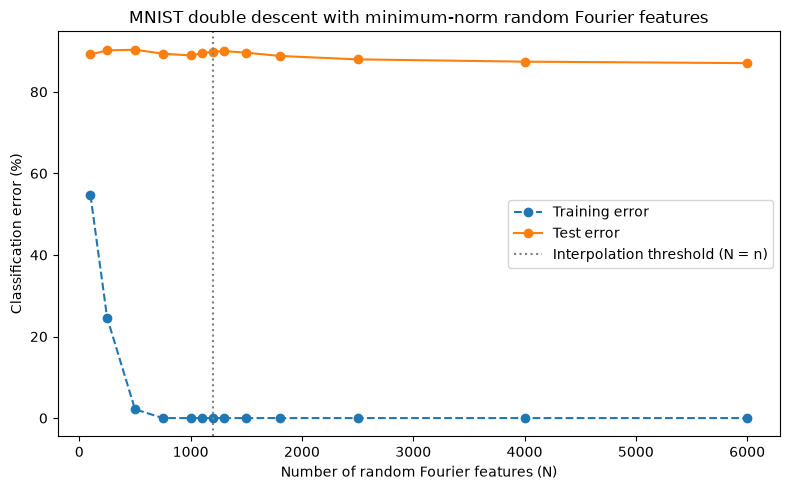

In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision.datasets import MNIST
import torch.nn.functional as F

# The paper uses n=10,000 and up to 60,000 features. Use a smaller, reproducible
# subset/sweep while keeping feature counts on both sides of interpolation.
SEED = 2026
N_TRAIN = 1_200
N_TEST = 2_500
FEATURE_COUNTS = (100, 250, 500, 750, 1_000, 1_100, 1_200, 1_300,
                  1_500, 1_800, 2_500, 4_000, 6_000)

mnist_train = MNIST(root="../data", train=True, download=True)
mnist_test = MNIST(root="../data", train=False, download=True)

rng = torch.Generator().manual_seed(SEED)
train_indices = torch.randperm(len(mnist_train), generator=rng)[:N_TRAIN]
test_indices = torch.randperm(len(mnist_test), generator=rng)[:N_TEST]

x_train = mnist_train.data[train_indices].reshape(N_TRAIN, -1).float().div_(255.0)
y_train = mnist_train.targets[train_indices]
x_test = mnist_test.data[test_indices].reshape(N_TEST, -1).float().div_(255.0)
y_test = mnist_test.targets[test_indices]

# Nested random Fourier features: the same frequency vectors are reused as N grows.
torch.manual_seed(SEED)
frequencies = torch.randn(x_train.shape[1], max(FEATURE_COUNTS))
train_projection = x_train @ frequencies
test_projection = x_test @ frequencies
phi_train_all = torch.exp(1j * train_projection).to(torch.complex64)
phi_test_all = torch.exp(1j * test_projection).to(torch.complex64)
targets = F.one_hot(y_train, num_classes=10).to(torch.complex64)

train_errors = []
test_errors = []

for n_features in FEATURE_COUNTS:
    phi_train = phi_train_all[:, :n_features]
    phi_test = phi_test_all[:, :n_features]

    # SVD-based least squares returns the minimum-norm coefficients at/above
    # interpolation, matching the paper's tie-breaking rule.
    coefficients = torch.linalg.lstsq(phi_train, targets, driver="gelsd").solution
    train_scores = (phi_train @ coefficients).real
    test_scores = (phi_test @ coefficients).real
    train_error = (train_scores.argmax(dim=1) != y_train).float().mean().item() * 100
    test_error = (test_scores.argmax(dim=1) != y_test).float().mean().item() * 100
    train_errors.append(train_error)
    test_errors.append(test_error)
    print(
        f"N={n_features:>5}: train error={train_error:5.2f}%, "
        f"test error={test_error:5.2f}%"
    )

plt.figure(figsize=(8, 5))
plt.plot(FEATURE_COUNTS, train_errors, "o--", label="Training error")
plt.plot(FEATURE_COUNTS, test_errors, "o-", label="Test error")
plt.axvline(N_TRAIN, color="grey", linestyle=":", label="Interpolation threshold (N = n)")
plt.xlabel("Number of random Fourier features (N)")
plt.ylabel("Classification error (%)")
plt.title("MNIST double descent with minimum-norm random Fourier features")
plt.legend()
plt.tight_layout()
plt.show()

### Why double descent can happen

In the classical regime, a small feature set cannot fit all training examples, so adding features can reduce underfitting and lower test error. Near the interpolation threshold, the model has just enough degrees of freedom to fit the training set. The fitted minimum-norm coefficients can become highly sensitive to the particular sample, so small changes in examples can cause large changes in the predictor; this can make test error rise even as training error approaches zero. With many more features, there are many interpolating solutions, and the minimum-norm solution can spread the fit across a richer basis and become more stable or smoother, so test error can fall again. This is one way to understand the second descent; it is not a claim that every model or dataset must show the same curve.

This interpretation follows Belkin et al. (2019), who connect the second descent to the minimum-norm interpolating solution and its function-space regularity, and Nakkiran et al. (2020), who document related deep-double-descent behavior across modern neural-network settings ([paper](https://arxiv.org/abs/1912.02292)). The observed curve here is empirical: if a particular random sample or reduced sweep makes the peak subtle, report that rather than implying the curve was guaranteed.

**Question 4**
